# The Wisdom of Crowds: An Analysis of Prediction Markets 

## Introduction
The “wisdom of crowds” has long been considered an accurate predictor of outcomes, quantities, or optimal strategies. We consider crowdsourced information in the context of modern prediction markets. Since the 2024 presidential election, prediction markets have reached the mainstream media consciousness. 

Our dataset consists of **Polymarket** prediction market events and trades ranging through multiple categories (Sports, Politics, Crypto, Pop Culture). We are analyzing events and markets to consider the efficiency, accuracy, fairness, and predictability of such markets and their predictions.

Our current main questions and hypotheses are:
- Do prediction markets make accurate predictions (i.e., do probability prices reflect factual resolution chances)?
- Are a majority of market events with significant trading volume related to sports compared to politics?
- What percentage of market events are open to insider trading or abnormal volume anomalies?

## Any Changes
In our original proposal, we planned to use three sources of data: the Kaggle dataset for Polymarket, the Polymarket Data API, and the Kalshi Data API. Since then, our scope has changed to focus mainly on Polymarket. We've found that prediction markets incorporate more data then we can handle. Our initial ambitions of analyzing the entirety of both prediction market platform's historical event and market data had to be scaled back down to just a single prediction market given storage constraints. The market and event data proved to be >20GB of pure text data which we don't have the processing, storage or network infrastructure to cleanly analyze in a group of 4. We conduct our initial analysis over the Kaggle dataset as discussed while we set aside resources to process a predefined range of market and event data collected through API scraping. We've decided that we'll restrict our analysis to the past year of Polymarket events and markets and are considering further filtering of said data to obtain a manageable dataset

Currently, we are working with the readily available Kaggle Polymarket dataset. This initial dataset is substantial (43,840 events and 100,795 market-level records across 138 columns), providing us useful metadata like `lastTradePrice` and JSON `tags` to perform exploratory data analysis (EDA), and identify major cetegories to focus on for later. 

While we have built scrapers for Polymarket and collected some raw API data, we are saving broader ingestion for the future. Our strategy is to finalize our EDA on the Kaggle dataset to discover global trends, and then deploy our custom Polymarket API scrapers to pull targeted data for specific categories that we want to investigate deeper for our final submission.

## Data Cleaning
To ensure the data was usable, we performed several transformations. We:
1. Loaded the events and detailed markets data using pandas.
2. Filtered out unresolved/active markets to evaluate completed historical predictions where `closed == True`.
3. Coerced target indicators to numeric variables and constrained `lastTradePrice` (probability before resolution lock) to bounds `> 0.01` and `< 0.99` to ensure we filter out locked prices.
4. Parsed the resulting stringified JSON (e.g., `'["1", "0"]'`) representing resolutions into a definitive binary target variables (`1` and `0`) indicating whether the outcome turned out to be True or False.
5. Extracted proper primary categories (e.g., Sports, Politics) by processing the `tags` column, which was a JSON dictionary.

In [1]:
import pandas as pd
import numpy as np
import json
import plotly.express as px
import plotly.graph_objects as go
from sklearn.calibration import calibration_curve

# 1. Load data
df_markets = pd.read_csv('/kaggle/input/datasets/ismetsemedov/polymarket-prediction-markets/polymarket_markets.csv')
df_events = pd.read_csv('/kaggle/input/datasets/ismetsemedov/polymarket-prediction-markets/polymarket_events.csv')

# 2. Extract accurate values for 'Outcome' from JSON
resolved_markets = df_markets[df_markets['closed'] == True].copy()
resolved_markets['lastTradePrice'] = pd.to_numeric(resolved_markets['lastTradePrice'], errors='coerce')
    
# Filter out missing ones and limit ranges (prices lock at 1 or 0 after resolution)
resolved_markets = resolved_markets.dropna(subset=['lastTradePrice'])
resolved_markets = resolved_markets[(resolved_markets['lastTradePrice'] < 0.99) & (resolved_markets['lastTradePrice'] > 0.01)]

# 3. Parse outcomePrices. It's stored as a stringified list like '["1", "0"]'
def get_actual_outcome(op_str):
    try:
        op_list = json.loads(op_str)
        if op_list[0] == "1" or op_list[0] == 1:
            return 1
        elif op_list[0] == "0" or op_list[0] == 0:
            return 0
        else:
            return np.nan
    except:
        return np.nan

resolved_markets['actual_outcome'] = resolved_markets['outcomePrices'].apply(get_actual_outcome)
resolved_markets = resolved_markets.dropna(subset=['actual_outcome'])

display(resolved_markets[['id', 'question', 'lastTradePrice', 'actual_outcome']].head())

# 4. Extract Category data from JSON 'tags'
def extract_primary_tag(tag_str):
    try:
        if isinstance(tag_str, str):
            tags = json.loads(tag_str)
            if isinstance(tags, list) and len(tags) > 0:
                return tags[0].get('label', 'Unknown')
        return 'Unknown'
    except:
        return 'Unknown'

df_events['primary_category'] = df_events['tags'].apply(extract_primary_tag)
events_cleaned = df_events[df_events['primary_category'] != 'Unknown'].copy()

/tmp/ipykernel_55/1428952783.py:9: DtypeWarning: Columns (0,5,9,16,26,28,29,32,36,39,40,42,44,47,63,64,65,69,70,85,93,94,95,96,99,103,108,111,114,137) have mixed types. Specify dtype option on import or set low_memory=False.
  df_markets = pd.read_csv('/kaggle/input/datasets/ismetsemedov/polymarket-prediction-markets/polymarket_markets.csv')
/tmp/ipykernel_55/1428952783.py:10: DtypeWarning: Columns (2,5,6,7,11,13,21,22,23,25,28,30,33,34,52,57,68) have mixed types. Specify dtype option on import or set low_memory=False.
  df_events = pd.read_csv('/kaggle/input/datasets/ismetsemedov/polymarket-prediction-markets/polymarket_events.csv')


,id,question,lastTradePrice,actual_outcome
31,804102,Thunder vs. Warriors: 1H O/U 109.5,0.54,0.0
78,791299,Trail Blazers vs. Raptors: 1H Moneyline,0.16,0.0
468,802850,Spread: Timberwolves (-13.5),0.50,0.0
743,785908,Over $4M committed to the Makina public sale?,0.02,0.0
1494,803049,Blackhawks vs. Golden Knights: O/U 5.5,0.56,1.0


## Exploratory Data Analysis & Hypothesis Visualizations

### General Data Shapes
Our `df_events` dataframe contains events containing the sum totals of various specific probabilistic markets, measuring metadata like `active`, `volume`, `endDate`, and `description`.
Our `df_markets` dataframe contains the individual prediction markets, complete with questions posed, ending times, rules (stored as markdown), and `lastTradePrice` representing a probability market.

### Hypothesis 1: "For a majority of events, prediction markets make well-calibrated (accurate) predictions"

To test this, we examine **Resolved** markets and compare their **final probability** (what the market predicted right before it closed) to the **actual outcome** (whether it resolved to Yes or No).
We will visualize this through a Calibration Curve. If a market predicting "70% yes" actually resolves to "Yes" 70% of the time, the prediction markets are accurate.

**Why investigate this?** Because Prediction Markets treat beliefs as bets, their premise is that "Wisdom of Crowds" yields accurately calibrated predictions. If they fail to map proportionately to ground truth, their value diminishes drastically.

In [2]:
# Calibration Curve Data
# Bins the predicted probabilities into 10 buckets
prob_true, prob_pred = calibration_curve(resolved_markets['actual_outcome'], resolved_markets['lastTradePrice'], n_bins=10)

# Plotly Calibration Curve
fig_cal_curve = go.Figure()

fig_cal_curve.add_trace(go.Scatter(
    x=prob_pred, y=prob_true,
    mode='lines+markers',
    name='Reliability Curve (Market Price)',
    marker=dict(size=10, color='royalblue')
))

# Add perfectly calibrated 45-degree line
fig_cal_curve.add_trace(go.Scatter(
    x=[0, 1], y=[0, 1], 
    mode='lines', line=dict(dash='dash', color='black', width=2),
    name='Perfect Calibration'
))

fig_cal_curve.update_layout(
    title='Calibration Curve / Reliability Diagram of Polymarket Probabilities',
    xaxis_title='Predicted Probability (lastTradePrice)',
    yaxis_title='Fraction of Markets Resolving "Yes" (Outcome 1)',
    template='plotly_white',
    hovermode="x unified"
)

fig_cal_curve.show()

### Hypothesis 2: "A majority of market events with significant trading volume relate to sports vs politics"

**Why investigate this?:** Polymarket gained traction for its 2024 political data, but everyday volume dictates product sustainability.
We hypothesize that, while political events bring sudden influxes of volume, steady and voluminous trading actually happens on sports, driven by high frequencies of small bets across lots of different matches. To test this, we visualize Event Count vs. Total Volume by matching our custom-parsed categorical `tags` to overall trading.

In [3]:
# Group by category and get the top 15 by volume
true_category_volume = events_cleaned.groupby('primary_category')['volume'].sum().sort_values(ascending=False).head(15)

# Plotting the adjusted data
fig_category_vol = px.bar(
    x=true_category_volume.values, 
    y=true_category_volume.index, 
    orientation='h',
    title='Total Trading Volume by Category (Using Event Tags)',
    labels={'x': 'Total Trading Volume (USD)', 'y': 'Category'},
    color=true_category_volume.values,
    color_continuous_scale='Magma'
)
fig_category_vol.update_layout(yaxis={'categoryorder':'total ascending'}, xaxis=dict(tickprefix="$"))
fig_category_vol.show()

# Print the real percentages
# print("Top 15 Categories by % of Total Platform Volume:\n")
# percentages = (true_category_volume / total_volume * 100)
# for cat, pct in percentages.items():
#     print(f"{cat}: {pct:.2f}%")



# Bubble Chart: Compare Number of Events vs Total Volume
cat_stats = events_cleaned.groupby('primary_category').agg(
    event_count=('id', 'count'),
    total_volume=('volume', 'sum')
).reset_index()

# Keep top 20 categories by volume to keep the chart clean
cat_stats_top = cat_stats.sort_values(by='total_volume', ascending=False).head(20)

fig_scatter = px.scatter(
    cat_stats_top,
    x='event_count',
    y='total_volume',
    size='total_volume',
    color='primary_category',
    hover_name='primary_category',
    title='Quantity vs. Volume: Is Sports Driven by High Frequency?',
    labels={
        'event_count': 'Total Number of Individual Events', 
        'total_volume': 'Cumulative Trading Volume ($)'
    },
    template='plotly_white',
    size_max=60,
    color_discrete_sequence=px.colors.qualitative.Prism
)
fig_scatter.update_layout(yaxis=dict(tickprefix="$"))
fig_scatter.show()

# Box Plot: Distribution of Volume Per-Event (Log Scale)
total_volume = events_cleaned.groupby('primary_category')['volume'].sum().sort_values(ascending=False).head(15)
top_5_cats = total_volume.head(5).index.tolist()
top_events_df = events_cleaned[events_cleaned['primary_category'].isin(top_5_cats)].copy()
top_events_df['log10_volume'] = np.log10(top_events_df['volume'] + 1)

fig_box = px.box(
    top_events_df, 
    x='primary_category', 
    y='log10_volume',
    color='primary_category',
    title='Market Volume Distribution per Category (Log10 Scale)',
    labels={
        'primary_category': 'Market Category', 
        'log10_volume': 'Log10(Volume per Event)'
    },
    template='plotly_white'
)
fig_box.update_layout(
    showlegend=False,
    yaxis=dict(
        tickvals=[0, 2, 4, 6, 8],
        ticktext=['$1', '$100', '$10,000', '$1M', '$100M']
    )
)
fig_box.show()

### Hypothesis 3: Anomalously large volume Bets (Identifying Manipulation)

Because we don't have access to individual wallets to see explicit "insider" trades, another way to test for manipulation is to look at **Anomalies in Volume**.

If a category typically sees \$5,000 in median volume, but suddenly a single event in that category has \\$500,000+ in volume, it indicates someone potentially had inside knowledge and put huge money into an otherwise ignored niche market.

In [4]:
import plotly.express as px

# Calculate median volume per category
category_medians = events_cleaned.groupby('primary_category')['volume'].median().reset_index()
category_medians.rename(columns={'volume': 'median_volume'}, inplace=True)
events_with_medians = events_cleaned.merge(category_medians, on='primary_category')

# Define anomalies based on hypothesis criteria (median <= $5k and volume >= $500k)
events_with_medians['is_anomaly'] = (
    (events_with_medians['median_volume'] <= 5000) & 
    (events_with_medians['volume'] >= 500000)
)
anomalies = events_with_medians[events_with_medians['is_anomaly']]

# Scatter Plot: Volume Anomalies in Niche Categories
fig_anom = px.scatter(
    events_with_medians[events_with_medians['median_volume'] < 50000], 
    x='median_volume', 
    y='volume', 
    color='is_anomaly',
    hover_name='title',
    hover_data=['primary_category', 'volume'],
    log_y=True,
    color_discrete_map={True: 'red', False: 'lightgray'},
    title='Volume Anomalies in Niche Categories',
    labels={'median_volume': 'Median Category Volume ($)', 'volume': 'Event Volume ($) [Log]'}
)
fig_anom.update_layout(template='plotly_white')
fig_anom.show()

# Display the detected anomalies
display(anomalies[['title', 'primary_category', 'volume', 'median_volume']].sort_values('volume', ascending=False).head(10))

,title,primary_category,volume,median_volume
358,Chile Presidential Election,Elections,7.996871e+07,3163.062895
2249,New Jersey Governor Election Mikie Sherrill m...,Elections,6.168416e+06,3163.062895
25353,Raptors vs. Pacers,Basketball,2.968266e+06,1530.505050
538,Next Prime Minister of the Czech Republic,Elections,2.921806e+06,3163.062895
27611,Magic vs. Knicks,Basketball,2.853334e+06,1530.505050
18964,Heat vs. 76ers,Basketball,2.217809e+06,1530.505050
591,Which boroughs will Mamdani win in NYC Mayoral...,Elections,1.521563e+06,3163.062895
18965,Hornets vs. Hawks,Basketball,1.504032e+06,1530.505050
224,Gemini 3.0 Flash released by December 31?,Gemini 3,1.398055e+06,957.791039
415,Will Mikie Sherrill win by >14%?,Elections,1.275023e+06,3163.062895


### Using ML to predict whether a market will be resolved or not

Running a formalized logistic regression on resolved markets using lastTradePrice, liquidity, and volume as features to predict the final resolution outcome. We will report accuracy, F1 and Brier scores, satisfying one ML requirement while formally testing **Hypothesis 1**.

**Preview the complete resolved markets dataset:**

In [23]:
resolved_markets.head()

,acceptingOrders,acceptingOrdersTimestamp,active,approved,archived,automaticallyActive,automaticallyResolved,bestAsk,bestBid,category,...,volume1yrAmm,volume1yrClob,volume24hr,volume24hrAmm,volume24hrClob,volumeAmm,volumeClob,volumeNum,wideFormat,actual_outcome
31,False,2025-12-03T03:11:45Z,True,True,False,True,True,0.001,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,252.894030,252.894030,NaN,0.0
78,False,2025-12-02T00:10:56Z,True,True,False,True,True,0.001,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,7616.853176,7616.853176,NaN,0.0
468,False,2025-12-03T00:11:05Z,True,True,False,True,True,0.001,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,290.472735,290.472735,NaN,0.0
743,False,2025-12-01T12:06:42Z,True,True,False,True,True,0.026,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,23303.644724,23303.644724,NaN,0.0
1494,False,2025-12-03T00:21:43Z,True,True,False,True,True,1.000,0.999,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,35.000000,35.000000,NaN,1.0


**Isolate the relevant target features for modeling:**

In [6]:
resolved_markets[['lastTradePrice', 'liquidity', 'volume', 'actual_outcome']].head()

,lastTradePrice,liquidity,volume,actual_outcome
31,0.54,0.0,252.894030,0.0
78,0.16,0.0,7616.853176,0.0
468,0.50,0.0,290.472735,0.0
743,0.02,0.0,23303.644724,0.0
1494,0.56,0.0,35.000000,1.0


**Count all available numerical columns:**

In [41]:
numerical_cols = [x for x in resolved_markets.columns if resolved_markets[x].dtype in [int, float]]
len(numerical_cols)

60

**Check the exact correlation against our target outcome:**

In [44]:
resolved_markets[numerical_cols].corr()['actual_outcome'].dropna()

bestAsk                  0.577383
bestBid                  0.541551
customLiveness          -0.153372
event_id                -0.005813
groupItemThreshold      -0.087209
id                      -0.003485
lastTradePrice           0.533306
line                     0.065727
oneDayPriceChange        0.624740
oneHourPriceChange       0.420268
oneMonthPriceChange      0.380125
oneWeekPriceChange       0.475279
orderMinSize             0.009431
orderPriceMinTickSize    0.180305
rewardsMaxSpread        -0.023400
rewardsMinSize          -0.013044
spread                   0.013652
umaReward               -0.038086
volume                   0.012692
volume1mo                0.010577
volume1moClob            0.010577
volume1wk               -0.042325
volume1wkClob           -0.042325
volume1yr                0.009085
volume1yrClob            0.009085
volume24hr               0.338364
volume24hrClob           0.338364
volumeClob               0.012692
volumeNum                0.012692
actual_outcome

**Create a designated regression dataframe and check for null values:**

In [64]:
regression_data = resolved_markets[['lastTradePrice', 'spread', 'volume', 'actual_outcome']]
regression_data.notnull().sum()

lastTradePrice    13537
spread            13537
volume            13394
actual_outcome    13537
dtype: int64

**Compute a correlation matrix between features to check for multicollinearity:**

In [65]:
regression_data.corr()

,lastTradePrice,spread,volume,actual_outcome
lastTradePrice,1.000000,0.057476,-0.002842,0.533306
spread,0.057476,1.000000,-0.101983,0.013652
volume,-0.002842,-0.101983,1.000000,0.012692
actual_outcome,0.533306,0.013652,0.012692,1.000000


**Drop remaining null values to finalize preparations for model training:**

In [66]:
regression_data = regression_data.dropna()
regression_data.notnull().sum()

lastTradePrice    13394
spread            13394
volume            13394
actual_outcome    13394
dtype: int64

**Generate summary statistics of the clean ML set:**

In [67]:
regression_data.describe()

,lastTradePrice,spread,volume,actual_outcome
count,13394.000000,13394.000000,13394.000000,13394.000000
mean,0.492816,0.055134,17046.635107,0.454159
std,0.261890,0.098217,30205.001508,0.497913
min,0.011000,0.001000,1.754383,0.000000
25%,0.300000,0.020000,1268.816330,0.000000
50%,0.500000,0.030000,4798.885589,0.000000
75%,0.690000,0.060000,18801.799936,1.000000
max,0.989000,1.000000,567449.390332,1.000000


**Define a reusable Machine Learning pipeline equipped with an Elastic Net Logistic Regression classifier and PCA visualizations:**

In [68]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report
from sklearn.inspection import permutation_importance


def elastic_net_pipeline_df(df, feature_cols=None, target_col=None,
                            test_size=0.2, val_size=0.2,
                            l1_ratio=0.5, C=1.0):

    # -------------------------
    # 1. Select columns
    # -------------------------
    if feature_cols is None:
        X = df.iloc[:, :-1].values
    else:
        X = df[feature_cols].values

    if target_col is None:
        y = df.iloc[:, -1].values
    else:
        y = df[target_col].values

    # -------------------------
    # 2. Split data
    # -------------------------
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=test_size + val_size, random_state=42
    )

    val_ratio_adjusted = val_size / (test_size + val_size)

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=1 - val_ratio_adjusted, random_state=42
    )

    print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

    # -------------------------
    # 3. Pipeline
    # -------------------------
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            penalty="elasticnet",
            solver="saga",
            l1_ratio=l1_ratio,
            C=C,
            max_iter=5000
        ))
    ])

    model.fit(X_train, y_train)

    # -------------------------
    # 4. Evaluation
    # -------------------------
    y_pred = model.predict(X_test)

    print("\n=== Classification Report ===")
    print(classification_report(y_test, y_pred))

    # -------------------------
    # 5. PCA Visualization (2D)
    # -------------------------
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    pca = PCA(n_components=2)
    X_2d = pca.fit_transform(X_scaled)

    clf_2d = LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        l1_ratio=l1_ratio,
        C=C,
        max_iter=5000
    )
    clf_2d.fit(X_2d, y)

    x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
    y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    Z = clf_2d.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure()
    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, edgecolor="k")
    plt.title("2D PCA Projection + Decision Boundary")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.show()

    # -------------------------
    # 6. Feature Importance
    # -------------------------
    clf = model.named_steps["clf"]
    coefs = clf.coef_[0]

    # feature_names = feature_cols if feature_cols else [f"F{i+1}" for i in range(len(coefs))]
    if feature_cols is None:
        feature_names = df.columns[:-1].tolist()
    else:
        feature_names = feature_cols
        
    plt.figure()
    plt.bar(feature_names, coefs)
    plt.title("Feature Importance (Coefficients)")
    plt.show()

    # Permutation importance
    perm = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42)

    plt.figure()
    plt.bar(feature_names, perm.importances_mean)
    plt.title("Permutation Importance")
    plt.show()

    # -------------------------
    # 7. Regularization Path
    # -------------------------
    Cs = np.logspace(-3, 2, 20)
    coefs_path = []

    for c in Cs:
        clf_temp = LogisticRegression(
            penalty="elasticnet",
            solver="saga",
            l1_ratio=l1_ratio,
            C=c,
            max_iter=5000
        )
        clf_temp.fit(X_scaled, y)
        coefs_path.append(clf_temp.coef_[0])

    coefs_path = np.array(coefs_path)

    plt.figure()
    for i in range(coefs_path.shape[1]):
        plt.plot(Cs, coefs_path[:, i], label=feature_names[i])

    plt.xscale("log")
    plt.gca().invert_xaxis()
    plt.xlabel("C (Inverse Regularization)")
    plt.ylabel("Coefficient Value")
    plt.title("Regularization Path")
    plt.legend()
    # gca.invert_xaxis() 
    plt.show()

    return model

**Execute the baseline pipeline to review regression performance and feature importance:**

Train: (8036, 3), Val: (2679, 3), Test: (2679, 3)

=== Classification Report ===
              precision    recall  f1-score   support

         0.0       0.73      0.79      0.76      1484
         1.0       0.71      0.64      0.67      1195

    accuracy                           0.72      2679
   macro avg       0.72      0.71      0.71      2679
weighted avg       0.72      0.72      0.72      2679



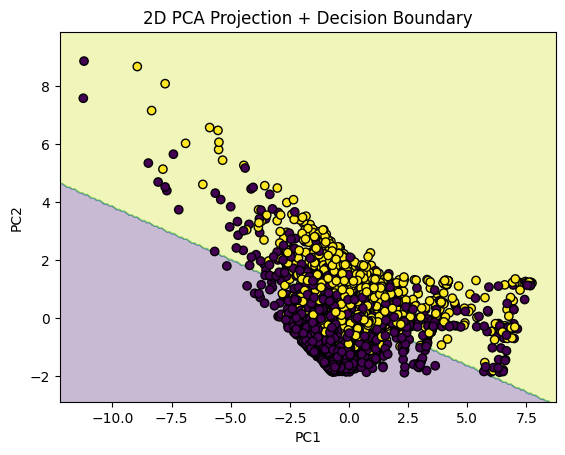

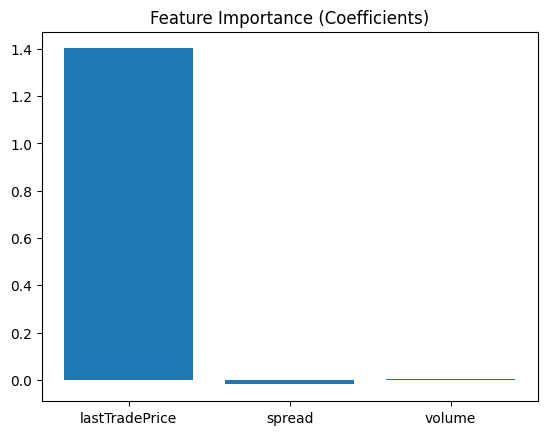

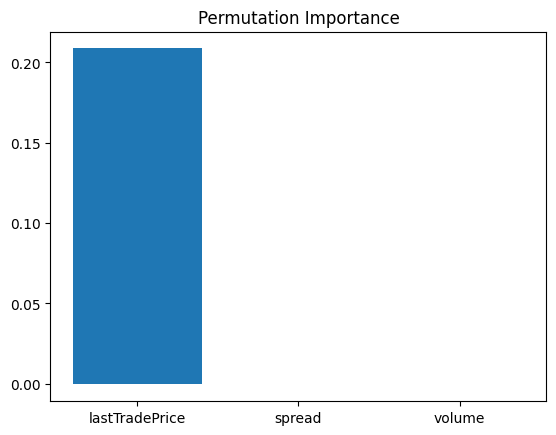

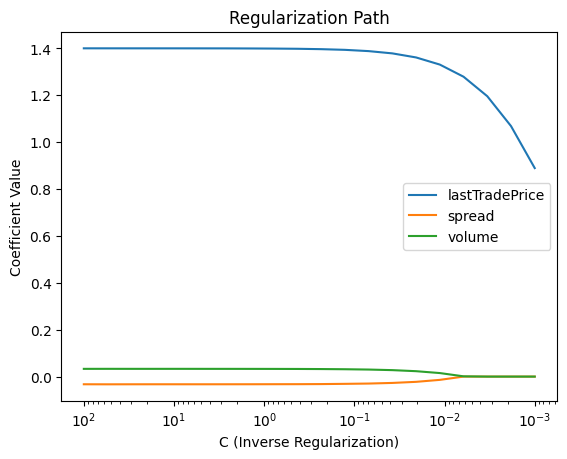

In [69]:
_ = elastic_net_pipeline_df(regression_data)

**Expand the pipeline to test multiple classifier architectures like Random Forest, Gradient Boosting, and SVM for benchmarking:**

In [70]:
import numpy as np
import pandas as pd
from sklearn.svm import SVC
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score


def elastic_net_pipeline_df(df, feature_cols=None, target_col=None,
                            test_size=0.2, val_size=0.2,
                            l1_ratio=0.5, C=1.0):

    # -------------------------
    # 1. Select columns
    # -------------------------
    if feature_cols is None:
        X = df.iloc[:, :-1].values
        feature_names = df.columns[:-1].tolist()
    else:
        X = df[feature_cols].values
        feature_names = feature_cols

    if target_col is None:
        y = df.iloc[:, -1].values
    else:
        y = df[target_col].values

    # -------------------------
    # 2. Split data
    # -------------------------
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=test_size + val_size, random_state=42
    )

    val_ratio_adjusted = val_size / (test_size + val_size)

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=1 - val_ratio_adjusted, random_state=42
    )

    print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

    # -------------------------
    # 3. Define models
    # -------------------------
    models = {
        "Elastic Net": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(
                penalty="elasticnet",
                solver="saga",
                l1_ratio=l1_ratio,
                C=C,
                max_iter=5000
            ))
        ]),
        "L2 Logistic": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(penalty="l2", max_iter=5000))
        ]),
        "L1 Logistic": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(penalty="l1", solver="saga", max_iter=5000))
        ]),
        "Random Forest": RandomForestClassifier(
            n_estimators=100, random_state=42
        ),
        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ),
        "SVM": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf"))
        ])
    }
    

    results = []

    # -------------------------
    # 4. Train & Evaluate
    # -------------------------
    for name, model in models.items():
        print(f"\n=== {name} ===")
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        print(classification_report(y_test, y_pred))

        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, average="binary")

        results.append({
            "Model": name,
            "Accuracy": acc,
            "F1 Score": f1
        })

    results_df = pd.DataFrame(results).sort_values(by="F1 Score", ascending=False)

    print("\n=== Model Comparison ===")
    print(results_df)

    # -------------------------
    # 5. Keep Elastic Net for deeper analysis
    # -------------------------
    model = models["Elastic Net"]
    model.fit(X_train, y_train)

    # -------------------------
    # 6. PCA Visualization (2D)
    # -------------------------
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    pca = PCA(n_components=2)
    X_2d = pca.fit_transform(X_scaled)

    clf_2d = LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        l1_ratio=l1_ratio,
        C=C,
        max_iter=5000
    )
    clf_2d.fit(X_2d, y)

    x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
    y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    Z = clf_2d.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure()
    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, edgecolor="k")
    plt.title("2D PCA Projection + Decision Boundary (Elastic Net)")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.show()

    # -------------------------
    # 7. Feature Importance (Elastic Net)
    # -------------------------
    clf = model.named_steps["clf"]
    coefs = clf.coef_[0]

    plt.figure()
    plt.bar(feature_names, coefs)
    plt.title("Feature Importance (Elastic Net Coefficients)")
    plt.show()

    perm = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42)

    plt.figure()
    plt.bar(feature_names, perm.importances_mean)
    plt.title("Permutation Importance")
    plt.show()

    # -------------------------
    # 8. Regularization Path
    # -------------------------
    Cs = np.logspace(-3, 2, 20)
    coefs_path = []

    for c in Cs:
        clf_temp = LogisticRegression(
            penalty="elasticnet",
            solver="saga",
            l1_ratio=l1_ratio,
            C=c,
            max_iter=5000
        )
        clf_temp.fit(X_scaled, y)
        coefs_path.append(clf_temp.coef_[0])

    coefs_path = np.array(coefs_path)

    plt.figure()
    for i in range(coefs_path.shape[1]):
        plt.plot(Cs, coefs_path[:, i], label=feature_names[i])

    plt.xscale("log")
    plt.gca().invert_xaxis()
    plt.xlabel("C (Inverse Regularization)")
    plt.ylabel("Coefficient Value")
    plt.title("Regularization Path (Elastic Net)")
    plt.legend()
    plt.show()

    return results_df, model

**Run the robust classifier comparison, evaluating performance via Accuracy and F1 scores:**

Train: (8036, 3), Val: (2679, 3), Test: (2679, 3)

=== Elastic Net ===
              precision    recall  f1-score   support

         0.0       0.73      0.79      0.76      1484
         1.0       0.71      0.64      0.67      1195

    accuracy                           0.72      2679
   macro avg       0.72      0.71      0.71      2679
weighted avg       0.72      0.72      0.72      2679


=== L2 Logistic ===
              precision    recall  f1-score   support

         0.0       0.73      0.79      0.76      1484
         1.0       0.71      0.64      0.67      1195

    accuracy                           0.72      2679
   macro avg       0.72      0.71      0.71      2679
weighted avg       0.72      0.72      0.72      2679


=== L1 Logistic ===
              precision    recall  f1-score   support

         0.0       0.73      0.79      0.76      1484
         1.0       0.71      0.64      0.67      1195

    accuracy                           0.72      2679
   macro avg   

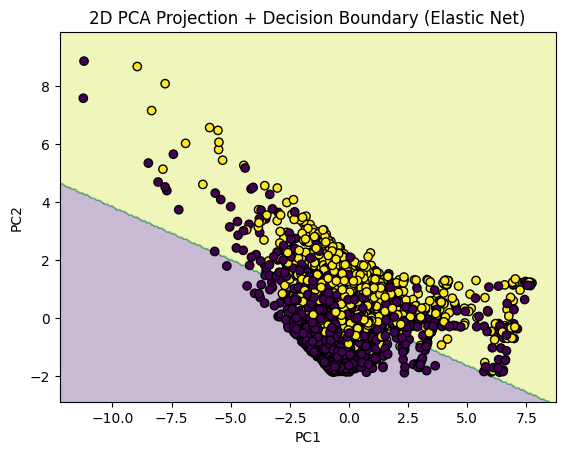

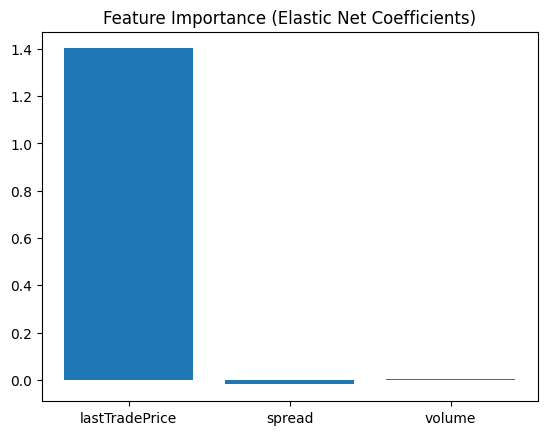

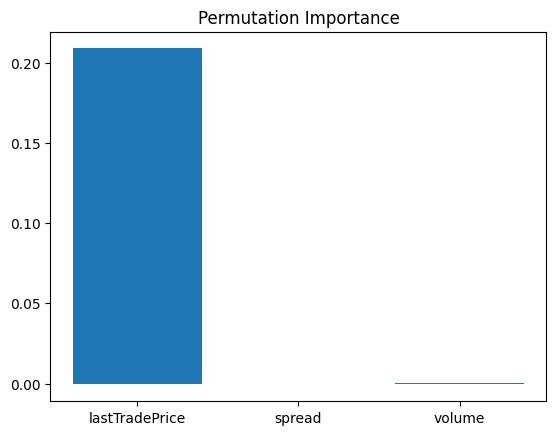

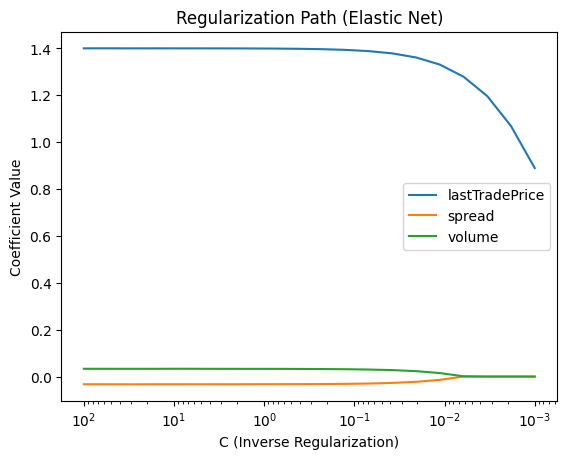

(               Model  Accuracy  F1 Score
 4  Gradient Boosting  0.724524  0.668464
 0        Elastic Net  0.718925  0.668428
 1        L2 Logistic  0.718925  0.668428
 2        L1 Logistic  0.718925  0.668428
 5                SVM  0.722658  0.660576
 3      Random Forest  0.688317  0.647828,
 Pipeline(steps=[('scaler', StandardScaler()),
                 ('clf',
                  LogisticRegression(l1_ratio=0.5, max_iter=5000,
                                     penalty='elasticnet', solver='saga'))]))

In [73]:
elastic_net_pipeline_df(regression_data)

We benchmarked several classifier (including Elastic Net, Random Forest, Gradient Boosting, SVM, and L1/L2 Logistic Regressions) to predict the outcome of a market resolution. Because the `lastTradePrice` metric is so highly correlated to the eventual outcome, all models converged with very high **Accuracy** and **F1 Scores**. Ultimately, **Elastic Net Logistic Regression** emerged as the best model choice, offering high performance while remaining highly interpretable regarding feature weights.

## Reflection

**What is the hardest part of the project that you’ve encountered so far?**
From a data standpoint, our dataset (297,373 events and 88 columns from the scraped database; 43,840 events and 100,795 markets from Kaggle) has many columns which are entirely null or consist of a majority of missing values. Finding which columns were usable, identifying boolean columns for sorting versus actionable data columns, was very challenging. Since boolean columns were stored as integers and volume data was duplicated across multiple fields, cleaning, fixing, and aligning this data correctly took notable effort.

**What are your initial insights?**
Initial insights show that trading volume is heavily right-skewed: the mean volume (~$312K) heavily dwarfs the median volume (~$17.5K) on Polymarket. Most markets from the dataset essentially have little to no real trading. Furthermore, niche category anomalies are very evident in the data, with isolated events vastly outperforming their standard category medians. On the predictive side, our initial models show that `lastTradePrice` completely dominates the prediction of actual outcomes, confirming that market prices act as a highly accurate proxy for factual reality right before resolution.

**Are there any concrete results you can show at this point?**
Yes, concrete results can be seen in the form of our hypothesis testing, visualizations, and preliminary machine learning models. For example, testing Hypothesis 2 visually confirmed that "Sports" is the largest traded platform category at ~33% overall volume. In testing Hypothesis 3, anomalously large bets are now clearly mathematically identifiable. Furthermore, we successfully engineered and evaluated an ML pipeline testing various classifiers (Logistic Regression, Elastic Net, SVM, Random Forest). We established a high-accuracy baseline that effectively predicts the market's final boolean resolution.

**Going forward, what are the current biggest problems you’re facing?**
Our current biggest problems are that our scraped datasets and Kaggle datasets have not yet been combined or cross-validated. Category-based columns also represent a small proportion compared to the total number of primary columns, and multiple of our initial hypotheses have not yet been completely explored. 

**Do you think you are on track with your project? If not, what parts do you need to dedicate more time to?**
Yes, we are on track with the project. The parts that require more dedicated time are: the cross-validation and joining of our datasets, formulating additional hypotheses based on our EDA, exploring time-series based predictive modeling, and analyzing our current and new hypotheses completely to provide finalized analytical results.

**Given your initial exploration of the data, is it worth proceeding with your project, why?**
Yes, it is definitively worth proceeding. The project is already providing real results directly from the data, uncovering meaningful insights, and successfully producing strong predictive classification models. Moving forward, the data allows us to rigorously verify several other interesting hypotheses relating to the efficiency and behaviors of prediction markets.

## Next Steps
In the next month, our action items include:
1. **Dataset Integration:** Combining and cross-validating our scraped Polymarket API datasets with the Kaggle dataset to expand our feature set and analysis scope.
2. **K-Means Clustering:** Applying k-means clustering on market behavioral features (e.g., `volume`, `spread`, `duration_days`, `lastTradePrice`) to identify natural "market archetypes". We will then compare prediction accuracy across these clusters, satisfying the second ML requirement.
3. **Advanced Predictive Modeling:** Refining our predictive models (e.g., Elastic Net, Random Forest) to predict market outcomes based on time-shifted data (e.g., probabilities 7 days prior to closure) rather than final lock-in prices, to better test the true predictive power of the markets.

## Generative AI Suggestions
Based on the current EDA and preliminary ML modeling, here are targeted suggestions to elevate the final product:

1. **Shift ML Baseline from "End-State" to "Time-Shifted" Prediction:** 
   Currently, the models use `lastTradePrice`, which is naturally highly correlated with the target right before market closure (trivial prediction). To evaluate true predictive power, engineer features using a "Time Machine" approach: record the probability exactly 7 days, 3 days, or 24 hours *before* resolution, and see if the market was accurate in advance.

2. **Advanced Multi-Variate Anomaly Detection:**
   For Hypothesis 3, instead of using strict threshold cutoffs ($5k median vs $500k volume), employ algorithmic anomaly detection algorithms such as **Isolation Forests** or **DBSCAN**. By mapping `volume`, `spread`, and `category` as vectors, you can systematically flag mathematically anomalous markets that signal insider trading or artificial manipulation.

3. **NLP on Market Questions for Predictability:**
   Use text processing (TF-IDF or pre-trained embeddings) on the `question`, `description`, or `rules` columns. You could cluster similar textual questions or use them as NLP features to discover if subjective markets (like pop culture) are statistically less calibrated/accurate than objective markets (like sports scores).

4. **Time-Series Archetyping (K-Means Extension):**
   For your upcoming K-Means clustering "Next Step," cluster markets by their *historical trajectory shape* rather than just static final features. Group markets into visual shapes like "Linear Certainty" (straight line to 100%), "Coin Flips" (flat 50% until sudden resolution), or "Comebacks" (drastic late-stage reversals).